# Bagian 2 – Load Data & Membangun Model (Acang)
**Tugas JST: Klasifikasi Jenis Sampah dengan CNN (VGG16 Transfer Learning)**

Notebook ini melanjutkan hasil Azmi (`data_split.zip`):
1. Memuat dataset dari Google Drive dengan `tf.data` (`image_dataset_from_directory`)
2. Menerapkan augmentasi dan normalisasi VGG16
3. Membangun model **VGG16 pretrained ImageNet (dibekukan) + GlobalAveragePooling + Dense 256 + Dropout 0,5 + Softmax 6 kelas**
4. Menampilkan `model.summary()`, jumlah parameter, dan diagram arsitektur untuk **slide 7**

**Sebelum menjalankan:**
- Tambahkan shortcut folder dari Azmi ke My Drive (klik kanan folder > *Organize* > *Add shortcut* > *My Drive*)
- Pilih GPU: **Runtime > Change runtime type > T4 GPU**
- Lalu **Runtime > Run all**. Saat diminta izin Google Drive, klik *Connect* dan pilih akunmu.

## 1. Import library dan pengaturan

In [2]:
import os, glob, shutil, zipfile, random
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

IMG_SIZE = (224, 224)      # ukuran input VGG16
BATCH_SIZE = 32
CLASSES = ["cardboard", "glass", "metal", "paper", "plastic", "trash"]
LABEL_ID = {"cardboard": "Kardus", "glass": "Kaca", "metal": "Logam",
            "paper": "Kertas", "plastic": "Plastik", "trash": "Residu"}

os.makedirs("figures", exist_ok=True)
print("TensorFlow", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU") or "tidak ada (cek Runtime > Change runtime type)")

TensorFlow 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Menghubungkan Google Drive dan mencari dataset dari Azmi

In [3]:
from google.colab import drive
drive.mount("/content/drive")

# Lokasi zip dari Azmi. Kalau shortcut folder sudah ditambahkan ke My Drive,
# file ada di MyDrive/Tugas_JST/data_split.zip
ZIP_DRIVE = "/content/drive/MyDrive/Tugas_JST/data_split.zip"

if not os.path.exists(ZIP_DRIVE):
    # cari otomatis kalau nama/letak folder berbeda
    hasil = glob.glob("/content/drive/MyDrive/*/data_split.zip") + glob.glob("/content/drive/MyDrive/data_split.zip")
    if hasil:
        ZIP_DRIVE = hasil[0]
    else:
        raise FileNotFoundError(
            "data_split.zip tidak ditemukan di My Drive. Buka folder yang dibagikan Azmi di Google Drive, "
            "klik kanan > Organize > Add shortcut > pilih My Drive, lalu jalankan ulang sel ini.")
print("Dataset ditemukan:", ZIP_DRIVE)

Mounted at /content/drive
Dataset ditemukan: /content/drive/MyDrive/Tugas_JST/data_split.zip


## 3. Ekstrak dataset dan cek jumlah gambar
Pembagian data dari Azmi: train 70%, validation 15%, test 15% (stratified).

In [4]:
# Salin ke Colab dulu (lebih cepat dibanding membaca langsung dari Drive), lalu ekstrak
SPLIT_DIR = "/content/data_split"
if not os.path.exists(SPLIT_DIR):
    shutil.copy(ZIP_DRIVE, "/content/data_split.zip")
    with zipfile.ZipFile("/content/data_split.zip") as z:
        z.extractall(SPLIT_DIR)

# Cek jumlah gambar per bagian dan per kelas
rekap = {}
for split in ["train", "val", "test"]:
    rekap[split] = {c: len(os.listdir(os.path.join(SPLIT_DIR, split, c))) for c in CLASSES}
rekap = pd.DataFrame(rekap)
rekap.index = [f"{LABEL_ID[c]} ({c})" for c in CLASSES]
rekap.loc["Total"] = rekap.sum()
rekap

,train,val,test
Kardus (cardboard),282,61,60
Kaca (glass),350,75,76
Logam (metal),287,61,62
Kertas (paper),416,89,89
Plastik (plastic),337,72,73
Residu (trash),96,21,20
Total,1768,379,380


## 4. Memuat data dengan `tf.data`
`image_dataset_from_directory` membaca gambar per folder kelas, mengubah ukuran ke 224×224, dan membuat label one-hot untuk 6 kelas.

In [5]:
def load(split, shuffle):
    return tf.keras.utils.image_dataset_from_directory(
        os.path.join(SPLIT_DIR, split), labels="inferred", label_mode="categorical",
        class_names=CLASSES, image_size=IMG_SIZE, batch_size=BATCH_SIZE,
        shuffle=shuffle, seed=SEED)

train_raw = load("train", True)
val_raw   = load("val", False)
test_raw  = load("test", False)

Found 1768 files belonging to 6 classes.
Found 379 files belonging to 6 classes.
Found 380 files belonging to 6 classes.


## 5. Augmentasi dan normalisasi VGG16
Augmentasi hanya untuk data train. Normalisasi memakai `vgg16.preprocess_input` (RGB ke BGR dan pengurangan rata-rata piksel ImageNet).

In [6]:
# Augmentasi (sama dengan yang ditentukan Azmi) dan normalisasi VGG16
augment = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),                      # ±18 derajat
    layers.RandomZoom(0.1),
    layers.RandomTranslation(0.1, 0.1),
    layers.RandomBrightness(0.1, value_range=(0, 255)),
], name="augmentasi")
preprocess = tf.keras.applications.vgg16.preprocess_input

AUTOTUNE = tf.data.AUTOTUNE
train_ds = (train_raw
            .map(lambda x, y: (augment(x, training=True), y), num_parallel_calls=AUTOTUNE)
            .map(lambda x, y: (preprocess(x), y), num_parallel_calls=AUTOTUNE)
            .prefetch(AUTOTUNE))
val_ds  = val_raw.map(lambda x, y: (preprocess(x), y), num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)
test_ds = test_raw.map(lambda x, y: (preprocess(x), y), num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)

xb, yb = next(iter(train_ds))
print("Bentuk satu batch gambar:", xb.shape)   # (32, 224, 224, 3)
print("Bentuk satu batch label :", yb.shape)   # (32, 6), one-hot
print("Jumlah batch train/val/test:", len(train_raw), len(val_raw), len(test_raw))

Bentuk satu batch gambar: (32, 224, 224, 3)
Bentuk satu batch label : (32, 6)
Jumlah batch train/val/test: 56 12 12


In [7]:
# Class weight, karena kelas trash (residu) jauh lebih sedikit
from sklearn.utils.class_weight import compute_class_weight
y_train = np.concatenate([[c] * len(os.listdir(os.path.join(SPLIT_DIR, "train", c))) for c in CLASSES])
cw = compute_class_weight("balanced", classes=np.array(CLASSES), y=y_train)
CLASS_WEIGHT = {i: float(w) for i, w in enumerate(cw)}
for i, c in enumerate(CLASSES):
    print(f"{LABEL_ID[c]:8s} ({c:9s}): {CLASS_WEIGHT[i]:.2f}")

Kardus   (cardboard): 1.04
Kaca     (glass    ): 0.84
Logam    (metal    ): 1.03
Kertas   (paper    ): 0.71
Plastik  (plastic  ): 0.87
Residu   (trash    ): 3.07


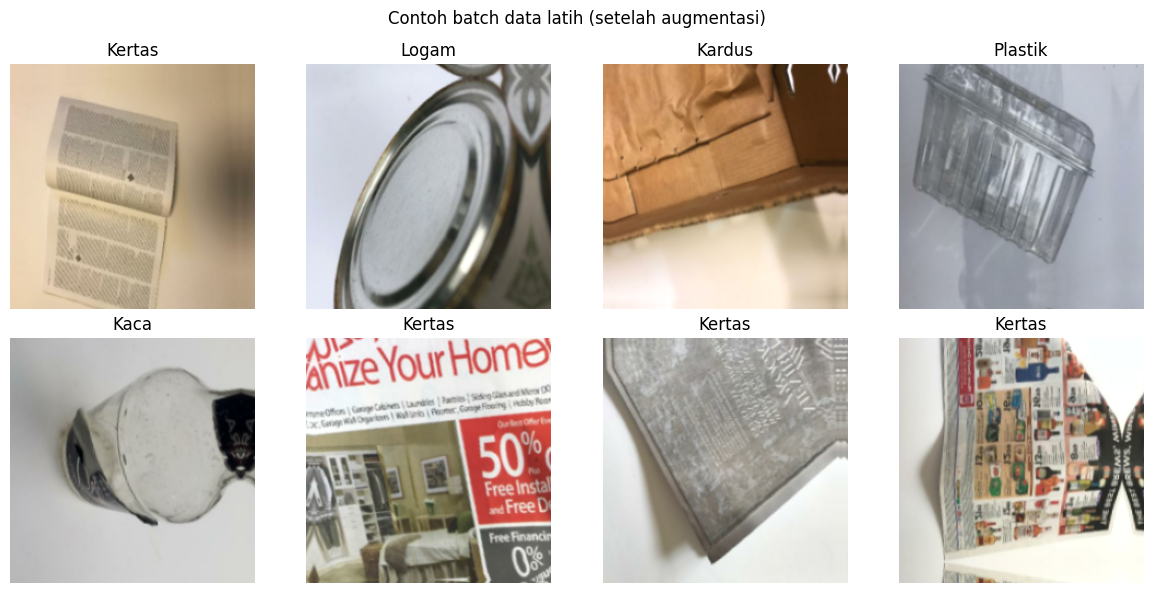

In [8]:
# Contoh satu batch data train setelah augmentasi (untuk memastikan data terbaca benar)
imgs, labs = next(iter(train_raw))
imgs_aug = augment(imgs, training=True)
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for ax, img, lab in zip(axes.ravel(), imgs_aug[:8], labs[:8]):
    ax.imshow(np.clip(img.numpy(), 0, 255).astype("uint8"))
    ax.set_title(LABEL_ID[CLASSES[int(np.argmax(lab))]]); ax.axis("off")
plt.suptitle("Contoh batch data latih (setelah augmentasi)")
plt.tight_layout(); plt.savefig("figures/contoh_batch_train.png", dpi=200); plt.show()

## 6. Membangun model VGG16 + lapisan tambahan
- **VGG16 pretrained ImageNet**, `include_top=False`: hanya 13 lapisan konvolusi yang dipakai, 3 lapisan FC aslinya dibuang
- **Dibekukan** (`trainable=False`): fitur dari ImageNet dipakai apa adanya, sehingga training lebih cepat dan tidak mudah overfitting
- **GlobalAveragePooling2D**: meratakan peta fitur 7×7×512 menjadi vektor 512 (parameternya jauh lebih sedikit dibanding Flatten yang menghasilkan 25.088)
- **Dense 256 + ReLU**: mempelajari kombinasi fitur untuk kelas sampah
- **Dropout 0,5**: mematikan 50% neuron secara acak saat training untuk mencegah overfitting
- **Dense 6 + Softmax**: keluaran berupa probabilitas 6 kelas

In [9]:
# 1) Basis VGG16 pretrained ImageNet tanpa lapisan klasifikasi aslinya (include_top=False)
base = tf.keras.applications.VGG16(weights="imagenet", include_top=False, input_shape=IMG_SIZE + (3,))
base.trainable = False   # dibekukan: bobot konvolusi tidak ikut dilatih

# 2) Lapisan tambahan untuk 6 kelas sampah
inputs  = layers.Input(shape=IMG_SIZE + (3,), name="input_gambar")
x       = base(inputs, training=False)
x       = layers.GlobalAveragePooling2D(name="global_avg_pool")(x)
x       = layers.Dense(256, activation="relu", name="dense_256")(x)
x       = layers.Dropout(0.5, name="dropout_0_5")(x)
outputs = layers.Dense(len(CLASSES), activation="softmax", name="softmax_6_kelas")(x)
model   = models.Model(inputs, outputs, name="VGG16_Klasifikasi_Sampah")

model.summary()

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "VGG16_Klasifikasi_Sampah"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_gambar (InputLayer)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vgg16 (Functional)              │ (None, 7, 7, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_avg_pool                 │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_256 (Dense)               │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_0_5 (Dropout)           │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ softmax_6_kelas (Dense)         │ (None, 6)              │         1,542 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,847,558 (56.64 MB)

 Trainable params: 132,870 (519.02 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

## 7. Ringkasan model dan jumlah parameter
Disimpan sebagai `figures/model_summary.csv` (per lapisan) dan `figures/tabel_parameter.csv` (total).

In [10]:
# Rekap jumlah parameter (untuk slide 7)
def hitung(ws): return int(sum(np.prod(w.shape) for w in ws))
def shp(s): return "×".join(str(v) for v in s[1:])

# 1) Ringkasan model per lapisan -> CSV
rows = [["Input", model.layers[0].name, "InputLayer", shp(model.layers[0].output.shape), 0, "-"]]
for l in base.layers[1:]:
    rows.append(["VGG16 (dibekukan)", l.name, l.__class__.__name__, shp(l.output.shape), l.count_params(), "Tidak"])
for l in model.layers[2:]:
    rows.append(["Lapisan tambahan", l.name, l.__class__.__name__, shp(l.output.shape), l.count_params(),
                 "Ya" if l.count_params() else "-"])
model_summary = pd.DataFrame(rows, columns=["Bagian", "Nama lapisan", "Tipe", "Ukuran output", "Jumlah parameter", "Dilatih"])
model_summary.insert(0, "No", range(1, len(model_summary) + 1))
model_summary.to_csv("figures/model_summary.csv", index=False, encoding="utf-8-sig")
display(model_summary)

# 2) Rekap total parameter -> CSV
tabel_param = pd.DataFrame({
    "Keterangan": ["Total parameter", "Parameter dilatih (lapisan tambahan)", "Parameter tidak dilatih (VGG16 dibekukan)"],
    "Jumlah": [model.count_params(), hitung(model.trainable_weights), hitung(model.non_trainable_weights)],
})
tabel_param.to_csv("figures/tabel_parameter.csv", index=False, encoding="utf-8-sig")
display(tabel_param)

,No,Bagian,Nama lapisan,Tipe,Ukuran output,Jumlah parameter,Dilatih
0,1,Input,input_gambar,InputLayer,224×224×3,0,-
1,2,VGG16 (dibekukan),block1_conv1,Conv2D,224×224×64,1792,Tidak
2,3,VGG16 (dibekukan),block1_conv2,Conv2D,224×224×64,36928,Tidak
3,4,VGG16 (dibekukan),block1_pool,MaxPooling2D,112×112×64,0,Tidak
4,5,VGG16 (dibekukan),block2_conv1,Conv2D,112×112×128,73856,Tidak
5,6,VGG16 (dibekukan),block2_conv2,Conv2D,112×112×128,147584,Tidak
6,7,VGG16 (dibekukan),block2_pool,MaxPooling2D,56×56×128,0,Tidak
7,8,VGG16 (dibekukan),block3_conv1,Conv2D,56×56×256,295168,Tidak
8,9,VGG16 (dibekukan),block3_conv2,Conv2D,56×56×256,590080,Tidak
9,10,VGG16 (dibekukan),block3_conv3,Conv2D,56×56×256,590080,Tidak


,Keterangan,Jumlah
0,Total parameter,14847558
1,Parameter dilatih (lapisan tambahan),132870
2,Parameter tidak dilatih (VGG16 dibekukan),14714688


## 8. Diagram arsitektur (untuk slide 7)

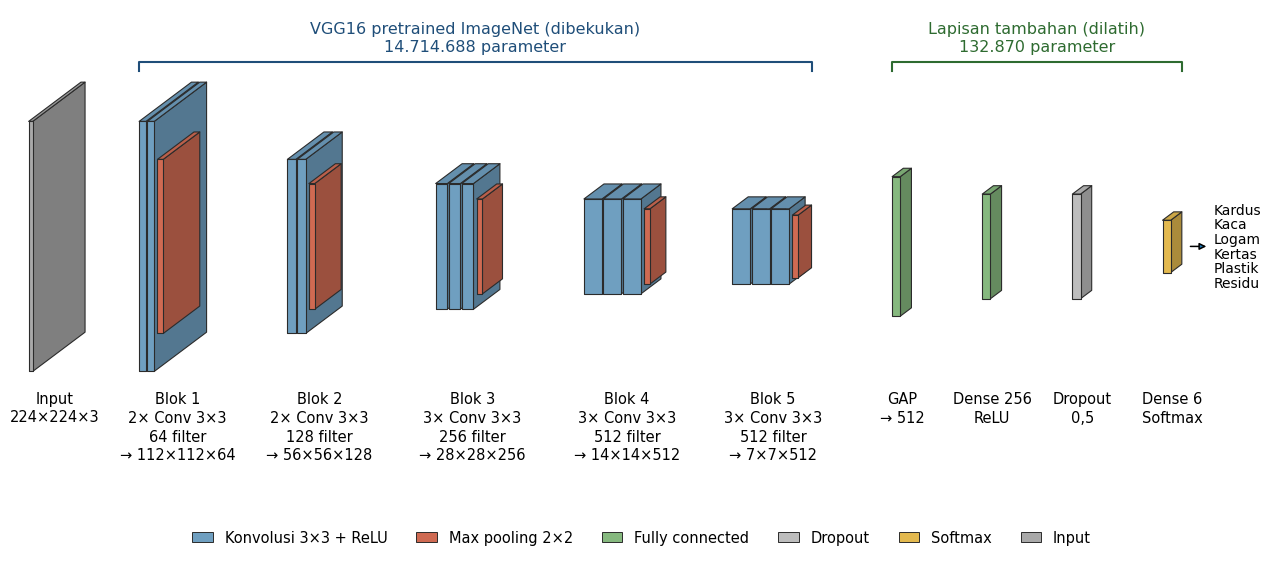

In [11]:
# Diagram arsitektur untuk slide 7 (gaya balok 3D seperti di paper CNN)
import matplotlib
from matplotlib.patches import Polygon, Patch, FancyBboxPatch
def fmt(n): return f"{n:,}".replace(",", ".")
def shp(s): return "×".join(str(v) for v in s[1:])


def cuboid(ax, x, w, h, d, fc, ec="#2b2b2b", lw=0.8):
    dx, dy = d * 0.6, d * 0.45
    y = -h / 2
    front = [(x, y), (x + w, y), (x + w, y + h), (x, y + h)]
    top   = [(x, y + h), (x + w, y + h), (x + w + dx, y + h + dy), (x + dx, y + h + dy)]
    side  = [(x + w, y), (x + w + dx, y + dy), (x + w + dx, y + h + dy), (x + w, y + h)]
    c = np.array(matplotlib.colors.to_rgb(fc))
    for pts, shade in [(side, 0.75), (top, 0.9), (front, 1.0)]:
        ax.add_patch(Polygon(pts, closed=True, fc=np.clip(c * shade, 0, 1), ec=ec, lw=lw, joinstyle="round"))
    return x + w

CONV, POOL, FC, DROP, SOFT, INP = "#6f9fc0", "#cf6a52", "#86b97f", "#bdbdbd", "#e3b94f", "#a9a9a9"
H  = lambda s: 0.7 + 3.6 * (s / 224) ** 0.65
D  = lambda s: 0.25 + 1.25 * (s / 224) ** 0.65
Wc = lambda c: 0.09 + 0.22 * (c / 512)

fig, ax = plt.subplots(figsize=(18, 6.4)); ax.set_aspect("equal"); ax.axis("off")
LABEL_Y = -H(224) / 2 - 0.35
FS = 10.5

x = 0.0
cuboid(ax, x, 0.07, H(224), D(224), INP)
ax.text(x + 0.45, LABEL_Y, "Input\n224×224×3", ha="center", va="top", fontsize=FS)
x = 1.9

spasial, chan, nconv = [224, 112, 56, 28, 14], [64, 128, 256, 512, 512], [2, 2, 3, 3, 3]
SLOT = 2.55
vgg0 = x
for b, (s, c, n) in enumerate(zip(spasial, chan, nconv), 1):
    xs = x
    xx = x
    for k in range(n):
        xx = cuboid(ax, xx, Wc(c), H(s), D(s), CONV) + 0.025
    xx = cuboid(ax, xx + 0.03, 0.1, H(s // 2), D(s // 2), POOL)
    cx = (xs + xx + D(s) * 0.6) / 2
    ax.text(cx, LABEL_Y, f"Blok {b}\n{n}× Conv 3×3\n{c} filter\n→ {s//2}×{s//2}×{c}", ha="center", va="top", fontsize=FS, linespacing=1.3)
    vgg1 = xx + D(s // 2) * 0.6
    x += SLOT
x += 0.2
head = [("GAP\n→ 512", FC, 2.4), ("Dense 256\nReLU", FC, 1.8), ("Dropout\n0,5", DROP, 1.8), ("Dense 6\nSoftmax", SOFT, 0.9)]
HS = 1.55
head0 = x
for t, col, h in head:
    cuboid(ax, x, 0.14, h, 0.32, col)
    ax.text(x + 0.17, LABEL_Y, t, ha="center", va="top", fontsize=FS, linespacing=1.3)
    head1 = x + 0.14 + 0.32 * 0.6
    x += HS
kelas = ["Kardus", "Kaca", "Logam", "Kertas", "Plastik", "Residu"]
xo = head1 + 0.55
ax.annotate("", xy=(xo - 0.08, 0), xytext=(head1 + 0.1, 0), arrowprops=dict(arrowstyle="-|>", lw=1.1))
for i, k in enumerate(kelas):
    ax.text(xo, 0.62 - i * 0.25, k, fontsize=FS - 0.5, va="center")

TOP = H(224) / 2 + D(224) * 0.45 + 0.35
def kurung(x0, x1, teks, col):
    ax.plot([x0, x0, x1, x1], [TOP - 0.15, TOP, TOP, TOP - 0.15], color=col, lw=1.5)
    ax.text((x0 + x1) / 2, TOP + 0.12, teks, ha="center", va="bottom", fontsize=11.5, color=col, linespacing=1.3)
kurung(vgg0, vgg1, f"VGG16 pretrained ImageNet (dibekukan)\n{fmt(base.count_params())} parameter", "#1f4e79")
kurung(head0, head1, f"Lapisan tambahan (dilatih)\n{fmt(hitung(model.trainable_weights))} parameter", "#2e6b30")

handles = [Patch(fc=c, ec="#2b2b2b", lw=0.7, label=l) for l, c in
           [("Konvolusi 3×3 + ReLU", CONV), ("Max pooling 2×2", POOL), ("Fully connected", FC), ("Dropout", DROP), ("Softmax", SOFT), ("Input", INP)]]
ax.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, -0.03), ncol=6, frameon=False, fontsize=FS, handlelength=1.4)
ax.set_xlim(-0.3, xo + 1.0); ax.set_ylim(LABEL_Y - 1.9, TOP + 0.9)
plt.savefig("figures/arsitektur_model.png", dpi=220, bbox_inches="tight", facecolor="white"); plt.show()

## 8b. Diagram lapisan model (untuk slide 7 atau lampiran)

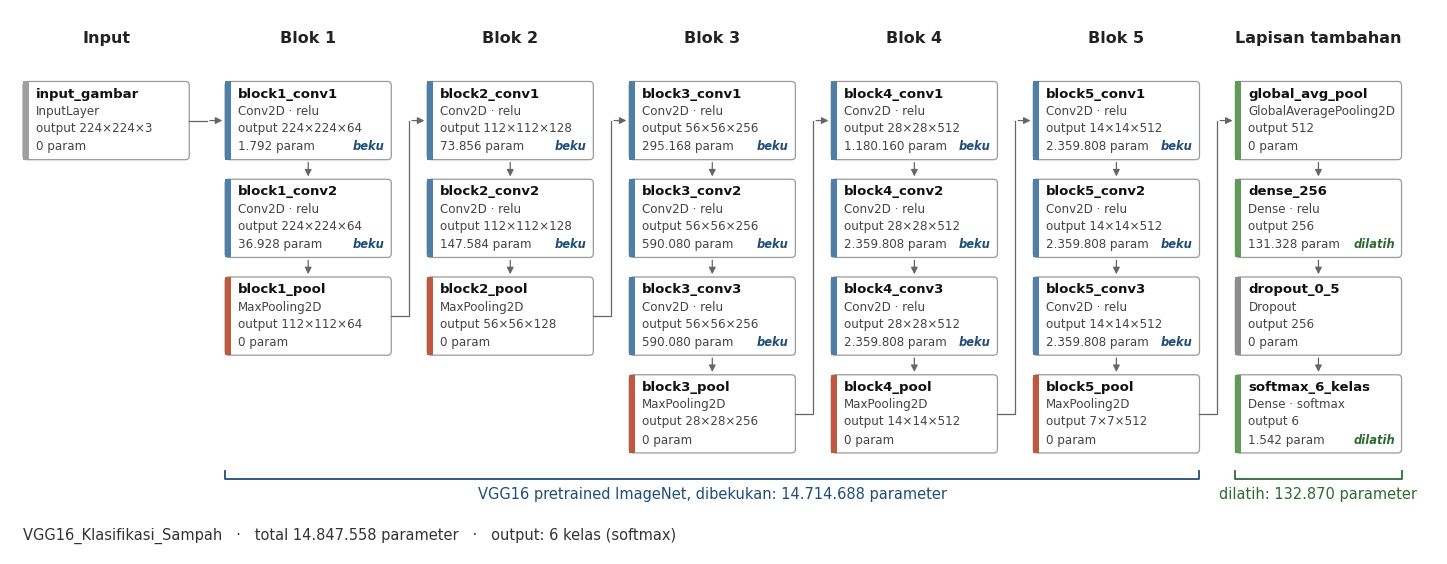

In [12]:
# Diagram lapisan model (pengganti plot_model bawaan Keras yang terlalu panjang ke bawah).
# Semua nama lapisan, ukuran output, dan jumlah parameter dibaca langsung dari model.
def plot_model_rapi(model, base, path):
    WARNA = {"InputLayer": "#9e9e9e", "Conv2D": "#4f7fa6", "MaxPooling2D": "#c0583f",
             "GlobalAveragePooling2D": "#5f9a57", "Dense": "#5f9a57", "Dropout": "#8c8c8c"}
    kolom = [("Input", [model.layers[0]])]
    for b in range(1, 6):
        kolom.append((f"Blok {b}", [l for l in base.layers if l.name.startswith(f"block{b}_")]))
    kolom.append(("Lapisan tambahan", model.layers[2:]))
    W, Hc, gx, gy = 2.55, 1.2, 0.55, 0.3
    nrow = max(len(c[1]) for c in kolom)
    fig, ax = plt.subplots(figsize=(len(kolom) * (W + gx) * 0.93, (nrow * (Hc + gy) + 1.6) * 0.93))
    ax.axis("off"); ax.set_aspect("equal")
    pos = []
    for ci, (judul, lays) in enumerate(kolom):
        x = ci * (W + gx)
        beku = ci in range(1, 6)
        ax.text(x + W / 2, 0.55, judul, ha="center", va="bottom", fontsize=11.5, weight="bold", color="#222")
        col_pos = []
        for ri, l in enumerate(lays):
            y = -ri * (Hc + gy) - Hc
            tipe = l.__class__.__name__
            act = getattr(l, "activation", None)
            act = act.__name__ if act is not None and act.__name__ != "linear" else ""
            par = l.count_params()
            ax.add_patch(FancyBboxPatch((x, y), W, Hc, boxstyle="round,pad=0,rounding_size=0.06",
                                        fc="white", ec="#9a9a9a", lw=0.9))
            ax.add_patch(FancyBboxPatch((x, y), 0.09, Hc, boxstyle="square,pad=0", fc=WARNA.get(tipe, "#777"), ec="none"))
            ax.text(x + 0.2, y + Hc - 0.19, l.name, fontsize=9.5, weight="bold", va="center", color="#111")
            ax.text(x + 0.2, y + Hc - 0.46, tipe + (f" · {act}" if act else ""), fontsize=8.6, va="center", color="#444")
            ax.text(x + 0.2, y + Hc - 0.72, f"output {shp(l.output.shape)}", fontsize=8.6, va="center", color="#444")
            ax.text(x + 0.2, y + 0.2, f"{fmt(par)} param", fontsize=8.6, va="center", color="#444")
            if par:
                ax.text(x + W - 0.1, y + 0.2, "beku" if beku else "dilatih", fontsize=8.3, ha="right", va="center",
                        color="#1f4e79" if beku else "#2e6b30", style="italic", weight="bold")
            col_pos.append((x, y))
        for (x0, y0), (x1, y1) in zip(col_pos[:-1], col_pos[1:]):
            ax.annotate("", xy=(x1 + W / 2, y1 + Hc), xytext=(x0 + W / 2, y0), arrowprops=dict(arrowstyle="-|>", lw=0.9, color="#666"))
        pos.append(col_pos)
    for a, b in zip(pos[:-1], pos[1:]):
        (x0, y0), (x1, y1) = a[-1], b[0]
        xm = x0 + W + gx / 2
        ax.plot([x0 + W, xm, xm], [y0 + Hc / 2, y0 + Hc / 2, y1 + Hc / 2], color="#666", lw=0.9)
        ax.annotate("", xy=(x1, y1 + Hc / 2), xytext=(xm, y1 + Hc / 2), arrowprops=dict(arrowstyle="-|>", lw=0.9, color="#666"))
    x0, x1 = 1 * (W + gx), 5 * (W + gx) + W
    yb = -nrow * (Hc + gy) - 0.1
    ax.plot([x0, x0, x1, x1], [yb + 0.12, yb, yb, yb + 0.12], color="#1f4e79", lw=1.3)
    ax.text((x0 + x1) / 2, yb - 0.12, f"VGG16 pretrained ImageNet, dibekukan: {fmt(base.count_params())} parameter",
            ha="center", va="top", fontsize=10.5, color="#1f4e79")
    xh = 6 * (W + gx)
    tr = int(sum(np.prod(w.shape) for w in model.trainable_weights))
    ax.plot([xh, xh, xh + W, xh + W], [yb + 0.12, yb, yb, yb + 0.12], color="#2e6b30", lw=1.3)
    ax.text(xh + W / 2, yb - 0.12, f"dilatih: {fmt(tr)} parameter", ha="center", va="top", fontsize=10.5, color="#2e6b30")
    ax.text(0, yb - 0.75, f"{model.name}   ·   total {fmt(model.count_params())} parameter   ·   output: 6 kelas (softmax)",
            fontsize=10.5, color="#333", va="top")
    ax.set_xlim(-0.2, len(kolom) * (W + gx)); ax.set_ylim(yb - 1.15, 1.1)
    plt.savefig(path, dpi=220, bbox_inches="tight", facecolor="white"); plt.show()


plot_model_rapi(model, base, "figures/plot_model_lapisan.png")

## 9. Kompilasi dan uji coba model

In [13]:
# Kompilasi model, siap dipakai untuk tahap training
model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
              loss="categorical_crossentropy", metrics=["accuracy"])

# Uji coba: satu batch masuk ke model, keluar 6 probabilitas per gambar
prob = model.predict(xb[:4], verbose=0)
print("Bentuk keluaran:", prob.shape)              # (4, 6)
print("Jumlah probabilitas tiap gambar:", prob.sum(axis=1).round(3))   # semuanya 1

Bentuk keluaran: (4, 6)
Jumlah probabilitas tiap gambar: [1. 1. 1. 1.]


## 10. Simpan hasil ke Google Drive
Isi folder `hasil_acang`: folder `figures` (gambar dan CSV untuk PPT) dan salinan notebook ini. Teman cukup klik dua kali notebook di Drive, pilih *Open with Google Colaboratory*, lalu **Run all**. Kalau aksesmu ke `Tugas_JST` hanya *viewer*, hasil disimpan ke `My Drive/hasil_acang`.

In [14]:
# Simpan hasil ke Google Drive (folder hasil_acang):
#   - figures/  : gambar dan tabel CSV untuk PPT
#   - notebook ini (.ipynb), supaya teman tinggal klik dua kali di Drive > Open with Colab > Run all
# Model tidak disimpan sebagai file .keras karena belum dilatih dan bisa dibangun ulang
# persis sama dengan menjalankan notebook ini.
import json

def simpan(OUT):
    os.makedirs(OUT, exist_ok=True)
    shutil.copytree("figures", os.path.join(OUT, "figures"), dirs_exist_ok=True)
    return OUT

try:
    OUT = simpan(os.path.join(os.path.dirname(ZIP_DRIVE), "hasil_acang"))
except (PermissionError, OSError) as e:
    print("Folder Tugas_JST tidak bisa ditulisi (", e.__class__.__name__, "), simpan ke My Drive saja.")
    OUT = simpan("/content/drive/MyDrive/hasil_acang")

# hapus file model lama kalau ada dari versi sebelumnya
for f in os.listdir(OUT):
    if f.endswith(".keras"):
        os.remove(os.path.join(OUT, f))

# simpan salinan notebook ini ke folder yang sama
try:
    from google.colab import _message
    nb = _message.blocking_request("get_ipynb", timeout_sec=60)["ipynb"]
    for c in nb["cells"]:
        if c["cell_type"] == "code":
            c["outputs"], c["execution_count"] = [], None
    with open(os.path.join(OUT, "02_Load_Data_dan_Model_Acang.ipynb"), "w") as f:
        json.dump(nb, f, ensure_ascii=False, indent=1)
except Exception as e:
    print("Notebook tidak tersimpan otomatis:", e)
    print("Simpan manual: File > Save a copy in Drive, lalu pindahkan ke folder", OUT)

print("Tersimpan di:", OUT)
print("Isi folder :", sorted(os.listdir(OUT)))
print("Isi figures:", sorted(os.listdir(os.path.join(OUT, "figures"))))

Tersimpan di: /content/drive/MyDrive/Tugas_JST/hasil_acang
Isi folder : ['02_Load_Data_dan_Model_Acang.ipynb', 'figures', 'model', 'riwayat_training.csv']
Isi figures: ['arsitektur_model.png', 'contoh_batch_train.png', 'grafik_training.png', 'model_summary.csv', 'plot_model_lapisan.png', 'riwayat_training.csv', 'skema_training.csv', 'tabel_parameter.csv']


## Lanjutan: tahap training
Model tidak perlu dimuat dari file. Setelah **Run all**, variabel yang sudah siap dipakai di sel berikutnya: `model`, `train_ds`, `val_ds`, `test_ds`, `CLASS_WEIGHT`.
Contoh: `model.fit(train_ds, validation_data=val_ds, epochs=20, class_weight=CLASS_WEIGHT, callbacks=[...])`

1. Training tahap 1 (VGG16 dibekukan)

In [15]:
import time, json
from tensorflow.keras import callbacks

OUT = globals().get("OUT", "/content/drive/MyDrive/hasil_acang")
MODEL_DIR = os.path.join(OUT, "model"); os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs("figures", exist_ok=True)

EPOCH_1 = 60
PATH_T1 = os.path.join(MODEL_DIR, "vgg16_sampah_tahap1.keras")

cb1 = [
    callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True, verbose=1),
    callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-6, verbose=1),
    callbacks.ModelCheckpoint(PATH_T1, monitor="val_loss", save_best_only=True),
]

t0 = time.time()
h1 = model.fit(train_ds, validation_data=val_ds, epochs=EPOCH_1,
               class_weight=CLASS_WEIGHT, callbacks=cb1)
print(f"Waktu tahap 1: {(time.time() - t0) / 60:.1f} menit | epoch berjalan: {len(h1.epoch)}")

Epoch 1/60
56/56 ━━━━━━━━━━━━━━━━━━━━ 75s 966ms/step - accuracy: 0.2421 - loss: 3.6387 - val_accuracy: 0.4881 - val_loss: 1.7645 - learning_rate: 1.0000e-04
Epoch 2/60
56/56 ━━━━━━━━━━━━━━━━━━━━ 30s 523ms/step - accuracy: 0.4118 - loss: 2.4099 - val_accuracy: 0.6016 - val_loss: 1.3423 - learning_rate: 1.0000e-04
Epoch 3/60
56/56 ━━━━━━━━━━━━━━━━━━━━ 39s 484ms/step - accuracy: 0.4836 - loss: 1.8965 - val_accuracy: 0.6596 - val_loss: 1.1474 - learning_rate: 1.0000e-04
Epoch 4/60
56/56 ━━━━━━━━━━━━━━━━━━━━ 29s 503ms/step - accuracy: 0.5288 - loss: 1.5664 - val_accuracy: 0.6675 - val_loss: 1.0354 - learning_rate: 1.0000e-04
Epoch 5/60
56/56 ━━━━━━━━━━━━━━━━━━━━ 42s 519ms/step - accuracy: 0.5650 - loss: 1.3985 - val_accuracy: 0.6966 - val_loss: 0.9572 - learning_rate: 1.0000e-04
Epoch 6/60
56/56 ━━━━━━━━━━━━━━━━━━━━ 31s 534ms/step - accuracy: 0.5792 - loss: 1.3084 - val_accuracy: 0.7150 - val_loss: 0.9128 - learning_rate: 1.0000e-04
Epoch 7/60
56/56 ━━━━━━━━━━━━━━━━━━━━ 30s 508ms/step - acc

2. Fine tuning blok 5

In [16]:
FINE_TUNE = True
EPOCH_2 = 40
PATH_T2 = os.path.join(MODEL_DIR, "vgg16_sampah_tahap2.keras")
h2, pilihan = None, "tahap 1 (VGG16 dibekukan)"

if FINE_TUNE:
    base.trainable = True
    for l in base.layers:
        l.trainable = l.name.startswith("block5_")
    n_latih = int(sum(np.prod(w.shape) for w in model.trainable_weights))
    print("Parameter dilatih saat fine tuning:", f"{n_latih:,}".replace(",", "."))  # 7.212.294

    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
                  loss="categorical_crossentropy", metrics=["accuracy"])
    cb2 = [
        callbacks.EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True, verbose=1),
        callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-7, verbose=1),
        callbacks.ModelCheckpoint(PATH_T2, monitor="val_loss", save_best_only=True),
    ]
    n1 = len(h1.epoch)
    h2 = model.fit(train_ds, validation_data=val_ds, epochs=n1 + EPOCH_2, initial_epoch=n1,
                   class_weight=CLASS_WEIGHT, callbacks=cb2)

    best1, best2 = min(h1.history["val_loss"]), min(h2.history["val_loss"])
    print(f"val_loss terbaik tahap 1: {best1:.4f} | tahap 2: {best2:.4f}")
    if best2 < best1:
        pilihan = "tahap 2 (fine tuning blok 5)"
    else:
        model = tf.keras.models.load_model(PATH_T1)   # fine tuning tidak membantu, pakai tahap 1
print("Model terpilih:", pilihan)

Parameter dilatih saat fine tuning: 7.212.294
Epoch 40/79
56/56 ━━━━━━━━━━━━━━━━━━━━ 46s 676ms/step - accuracy: 0.8518 - loss: 0.4414 - val_accuracy: 0.8470 - val_loss: 0.5190 - learning_rate: 1.0000e-05
Epoch 41/79
56/56 ━━━━━━━━━━━━━━━━━━━━ 32s 561ms/step - accuracy: 0.8592 - loss: 0.3794 - val_accuracy: 0.8549 - val_loss: 0.4796 - learning_rate: 1.0000e-05
Epoch 42/79
56/56 ━━━━━━━━━━━━━━━━━━━━ 40s 546ms/step - accuracy: 0.8818 - loss: 0.3392 - val_accuracy: 0.8549 - val_loss: 0.4880 - learning_rate: 1.0000e-05
Epoch 43/79
56/56 ━━━━━━━━━━━━━━━━━━━━ 29s 509ms/step - accuracy: 0.8937 - loss: 0.3007 - val_accuracy: 0.8522 - val_loss: 0.5117 - learning_rate: 1.0000e-05
Epoch 44/79
56/56 ━━━━━━━━━━━━━━━━━━━━ 0s 478ms/step - accuracy: 0.8909 - loss: 0.2653
Epoch 44: ReduceLROnPlateau reducing learning rate to 4.999999873689376e-06.
56/56 ━━━━━━━━━━━━━━━━━━━━ 29s 515ms/step - accuracy: 0.8937 - loss: 0.2796 - val_accuracy: 0.8522 - val_loss: 0.5114 - learning_rate: 1.0000e-05
Epoch 45/79


3. Riwayat training dan grafik

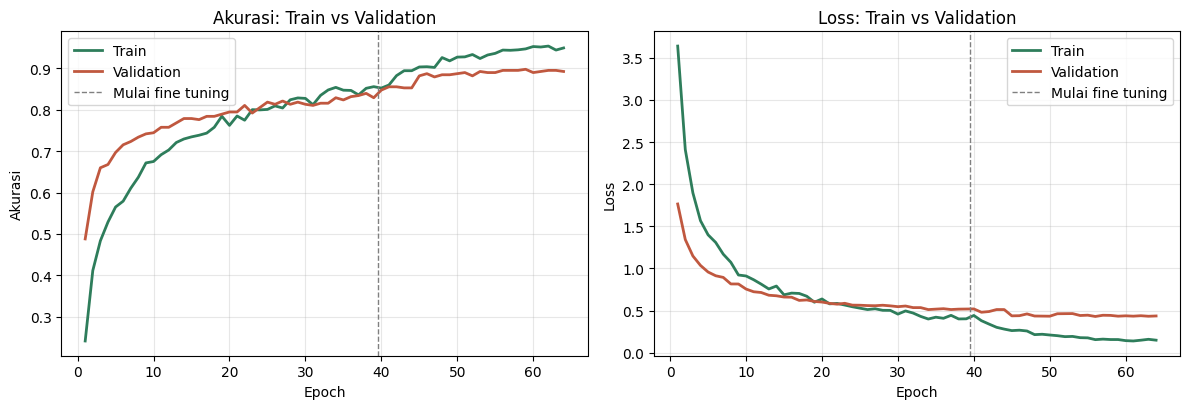

Akurasi train akhir: 0.9485 | validation akhir: 0.8918 | selisih: 0.0567


In [17]:
def gabung(*hs):
    frames = []
    for tahap, h in enumerate(hs, 1):
        if h is None:
            continue
        df = pd.DataFrame(h.history)       # tiap tahap dijadikan tabel sendiri
        df["tahap"] = tahap
        frames.append(df)
    return pd.concat(frames, ignore_index=True)   # kolom yang tidak ada diisi NaN

hist = gabung(h1, h2)
hist.insert(0, "epoch", range(1, len(hist) + 1))
hist.to_csv(os.path.join(OUT, "riwayat_training.csv"), index=False)
hist.to_csv("figures/riwayat_training.csv", index=False)

fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
for a, (m, jdl) in zip(ax, [("accuracy", "Akurasi"), ("loss", "Loss")]):
    a.plot(hist["epoch"], hist[m], label="Train", color="#2E7D5B", lw=2)
    a.plot(hist["epoch"], hist["val_" + m], label="Validation", color="#C0583F", lw=2)
    if h2 is not None:
        a.axvline(len(h1.epoch) + 0.5, color="gray", ls="--", lw=1, label="Mulai fine tuning")
    a.set_title(f"{jdl}: Train vs Validation"); a.set_xlabel("Epoch"); a.set_ylabel(jdl)
    a.grid(alpha=0.3); a.legend()
plt.tight_layout(); plt.savefig("figures/grafik_training.png", dpi=200); plt.show()

gap = hist["accuracy"].iloc[-1] - hist["val_accuracy"].iloc[-1]
print(f"Akurasi train akhir: {hist['accuracy'].iloc[-1]:.4f} | validation akhir: {hist['val_accuracy'].iloc[-1]:.4f} | selisih: {gap:.4f}")

4. Simpan model, riwayat, dan skema training

In [20]:
# 1) Model bersih tanpa state optimizer
model_final = tf.keras.models.clone_model(model)
model_final.set_weights(model.get_weights())
PATH_FINAL = os.path.join(MODEL_DIR, "vgg16_sampah_final.keras")
model_final.save(PATH_FINAL)
print("Ukuran model:", round(os.path.getsize(PATH_FINAL) / 1e6, 1), "MB")

# 2) Urutan kelas (penting untuk Raniyol)
with open(os.path.join(MODEL_DIR, "class_names.json"), "w") as f:
    json.dump({"classes": CLASSES, "label_id": LABEL_ID}, f, ensure_ascii=False, indent=1)

# 3) Skema training (slide 8)
skema = pd.DataFrame({
    "Komponen": ["Optimizer", "Learning rate tahap 1", "Learning rate fine tuning", "Batch size",
                 "Epoch maksimum tahap 1", "Epoch berjalan tahap 1", "Epoch berjalan tahap 2",
                 "Loss function", "Metrik", "Class weight", "Callback", "Model terpilih"],
    "Nilai": ["Adam", "1e-4", "1e-5 (blok 5 dibuka)" if h2 is not None else "tidak dipakai", BATCH_SIZE,
              EPOCH_1, len(h1.epoch), len(h2.epoch) if h2 is not None else 0,
              "Categorical crossentropy", "Accuracy", "Balanced (trash = 3,07)",
              "EarlyStopping (patience 5), ReduceLROnPlateau, ModelCheckpoint", pilihan]})
skema.to_csv("figures/skema_training.csv", index=False, encoding="utf-8-sig")
display(skema)

# 4) Salin semua keluaran ke Drive
shutil.copytree("figures", os.path.join(OUT, "figures"), dirs_exist_ok=True)
print("Isi folder hasil:", sorted(os.listdir(OUT)))
print("Isi folder model:", sorted(os.listdir(MODEL_DIR)))

Ukuran model: 117.2 MB


,Komponen,Nilai
0,Optimizer,Adam
1,Learning rate tahap 1,1e-4
2,Learning rate fine tuning,1e-5 (blok 5 dibuka)
3,Batch size,32
4,Epoch maksimum tahap 1,60
5,Epoch berjalan tahap 1,39
6,Epoch berjalan tahap 2,25
7,Loss function,Categorical crossentropy
8,Metrik,Accuracy
9,Class weight,"Balanced (trash = 3,07)"


Isi folder hasil: ['02_Load_Data_dan_Model_Acang.ipynb', 'figures', 'model', 'riwayat_training.csv']
Isi folder model: ['class_names.json', 'vgg16_sampah_final.keras', 'vgg16_sampah_tahap1.keras', 'vgg16_sampah_tahap2.keras']


KODE CONTOH UNTUK CODE RANIA

In [19]:
import numpy as np, tensorflow as tf
from sklearn.metrics import classification_report, confusion_matrix

model = tf.keras.models.load_model("/content/drive/MyDrive/hasil_acang/model/vgg16_sampah_final.keras")
y_true = np.concatenate([np.argmax(y, axis=1) for _, y in test_ds])
y_pred = np.argmax(model.predict(test_ds), axis=1)
print(classification_report(y_true, y_pred, target_names=CLASSES, digits=4))
print(confusion_matrix(y_true, y_pred))

# Prediksi satu gambar baru
def prediksi(path):
    img = tf.keras.utils.load_img(path, target_size=(224, 224))
    x = tf.keras.applications.vgg16.preprocess_input(np.expand_dims(tf.keras.utils.img_to_array(img), 0))
    p = model.predict(x, verbose=0)[0]
    return CLASSES[int(p.argmax())], float(p.max())

ValueError: File not found: filepath=/content/drive/MyDrive/hasil_acang/model/vgg16_sampah_final.keras. Please ensure the file is an accessible `.keras` zip file.